# Telecom Customer Churn & Revenue Retention Analysis

## 1. Business Problem

Customer churn occurs when customers stop using a company's products or services.

Customer churn directly affects:
- Revenue and profitability
- Customer retention
- Long-term business growth

## 2. Project Objectives

1. Analyse customer churn patterns.
2. Identify customer segments with high churn rates.
3. Examine the impact of contract types and payment methods.
4. Analyse monthly charges and revenue at risk.
5. Develop actionable customer retention recommendations.

## 3. Tools & Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- PostgreSQL
- Power BI

## 4. Project Workflow

Data Collection → Data Cleaning → Exploratory Data Analysis → SQL Analysis → Power BI Dashboard → Business Insights & Recommendations

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display dataset dimensions

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first 5 records

df.head()

Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Display dataset information
print("\nDATASET INFORMATION:")
df.info()

# Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

COLUMN NAMES:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043

In [3]:
# Check blank spaces in TotalCharges

blank_values = df['TotalCharges'].str.strip().eq('').sum()

print("Blank values in TotalCharges:", blank_values)

# Check duplicate records

print("Duplicate rows:", df.duplicated().sum())

# Check unique values in Churn

print("\nChurn categories:")
print(df['Churn'].value_counts())

Blank values in TotalCharges: 11
Duplicate rows: 0

Churn categories:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
# Identify records with blank TotalCharges

blank_records = df[df['TotalCharges'].str.strip() == '']

# Display relevant columns
blank_records[['customerID', 'tenure', 'MonthlyCharges',
               'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:
# Convert TotalCharges from text to numeric
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

# Replace missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify the cleaning
print("TotalCharges data type:", df['TotalCharges'].dtype)
print("Remaining missing values:", df['TotalCharges'].isnull().sum())
print("Customers with zero tenure:", (df['tenure'] == 0).sum())

TotalCharges data type: float64
Remaining missing values: 0
Customers with zero tenure: 11


In [6]:
# Group customers based on tenure

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 Months', '13-24 Months',
            '25-48 Months', '49-72 Months']
)

# Group customers based on monthly charges

df['MonthlyChargesCategory'] = pd.cut(
    df['MonthlyCharges'],
    bins=[0, 35, 70, float('inf')],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

# Display the new columns
df[['tenure', 'TenureGroup',
    'MonthlyCharges', 'MonthlyChargesCategory']].head(10)

,tenure,TenureGroup,MonthlyCharges,MonthlyChargesCategory
0,1,0-12 Months,29.85,Low
1,34,25-48 Months,56.95,Medium
2,2,0-12 Months,53.85,Medium
3,45,25-48 Months,42.30,Medium
4,2,0-12 Months,70.70,High
5,8,0-12 Months,99.65,High
6,22,13-24 Months,89.10,High
7,10,0-12 Months,29.75,Low
8,28,25-48 Months,104.80,High
9,62,49-72 Months,56.15,Medium


In [7]:
# Calculate customer churn and retention

total_customers = len(df)

churned_customers = (df['Churn'] == 'Yes').sum()
retained_customers = (df['Churn'] == 'No').sum()

churn_rate = (churned_customers / total_customers) * 100
retention_rate = (retained_customers / total_customers) * 100

print("CUSTOMER CHURN ANALYSIS")
print("-----------------------")
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

CUSTOMER CHURN ANALYSIS
-----------------------
Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54%
Retention Rate: 73.46%


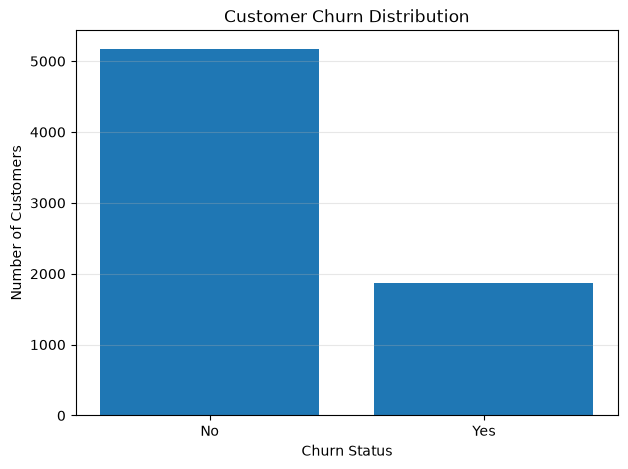

In [8]:
# Customer churn distribution

churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    churn_counts.index,
    churn_counts.values
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [9]:
# Calculate churn by contract type

contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print("CHURN RATE BY CONTRACT TYPE:")
display(contract_churn.round(2))

CHURN RATE BY CONTRACT TYPE:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


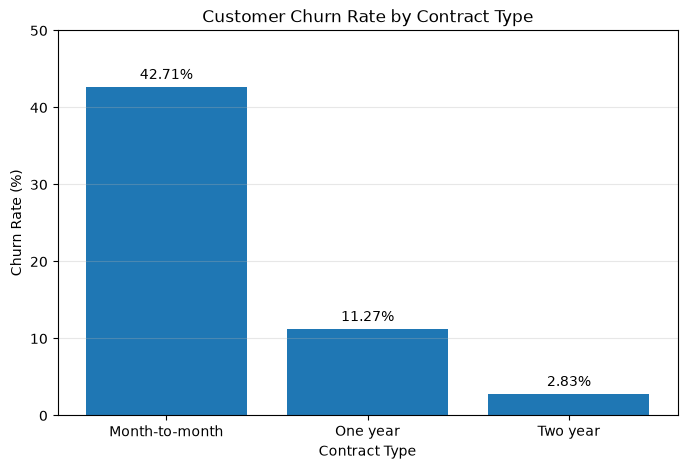

In [10]:
# Extract churn percentages

contract_churn_rate = contract_churn['Yes']

plt.figure(figsize=(8, 5))

plt.bar(
    contract_churn_rate.index,
    contract_churn_rate.values
)

plt.title('Customer Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 50)
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(contract_churn_rate.values):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

In [11]:
# Calculate churn rate by tenure group

tenure_churn = pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
) * 100

print("CHURN RATE BY CUSTOMER TENURE:")
display(tenure_churn.round(2))

CHURN RATE BY CUSTOMER TENURE:


Churn,No,Yes
TenureGroup,,
0-12 Months,52.56,47.44
13-24 Months,71.29,28.71
25-48 Months,79.61,20.39
49-72 Months,90.49,9.51


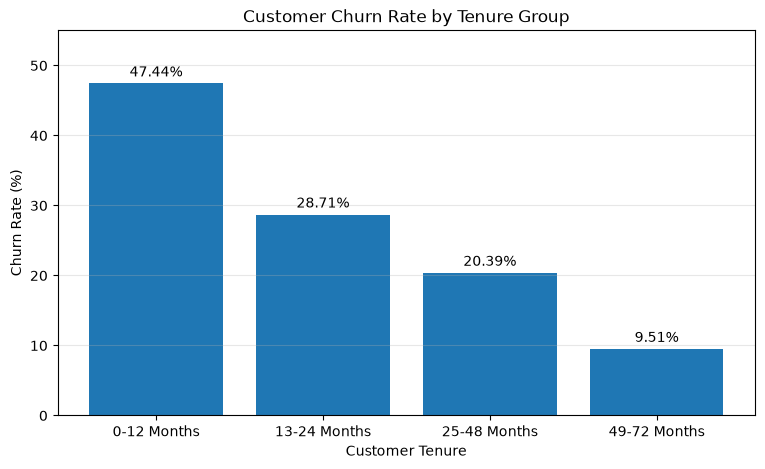

In [12]:
# Extract churn rate by tenure group

tenure_churn_rate = tenure_churn['Yes']

plt.figure(figsize=(9, 5))

plt.bar(
    tenure_churn_rate.index.astype(str),
    tenure_churn_rate.values
)

plt.title('Customer Churn Rate by Tenure Group')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')

plt.ylim(0, 55)
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(tenure_churn_rate.values):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.show()

In [13]:
# Compare monthly charges for churned and retained customers

monthly_churn = df.groupby('Churn')['MonthlyCharges'].mean()

print("AVERAGE MONTHLY CHARGES BY CHURN STATUS:")
display(monthly_churn.round(2))

AVERAGE MONTHLY CHARGES BY CHURN STATUS:


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

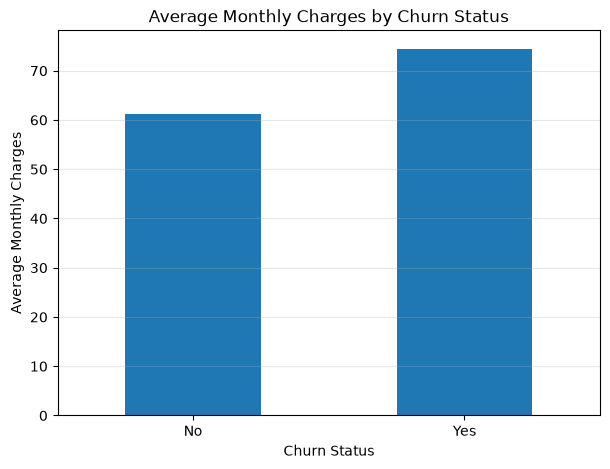

In [14]:
plt.figure(figsize=(7, 5))

monthly_churn.plot(kind='bar')

plt.title('Average Monthly Charges by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Average Monthly Charges')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [15]:
# Calculate churn rate by internet service

internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print("CHURN RATE BY INTERNET SERVICE:")
display(internet_churn.round(2))

CHURN RATE BY INTERNET SERVICE:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


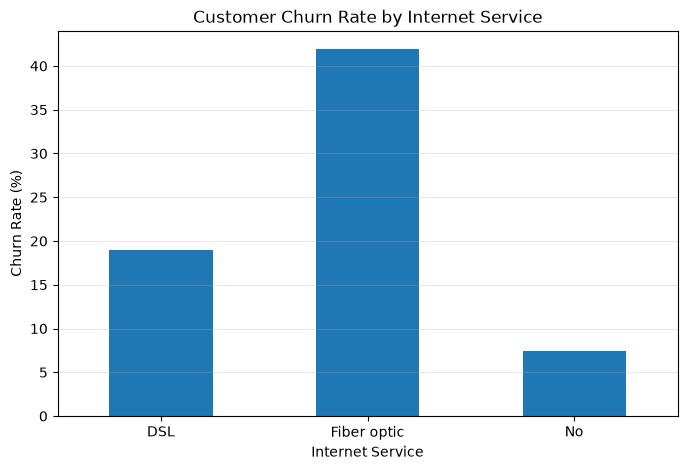

In [16]:
plt.figure(figsize=(8, 5))

internet_churn['Yes'].plot(kind='bar')

plt.title('Customer Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [17]:
# Calculate churn rate by payment method

payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print("CHURN RATE BY PAYMENT METHOD:")
display(payment_churn.round(2))

CHURN RATE BY PAYMENT METHOD:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


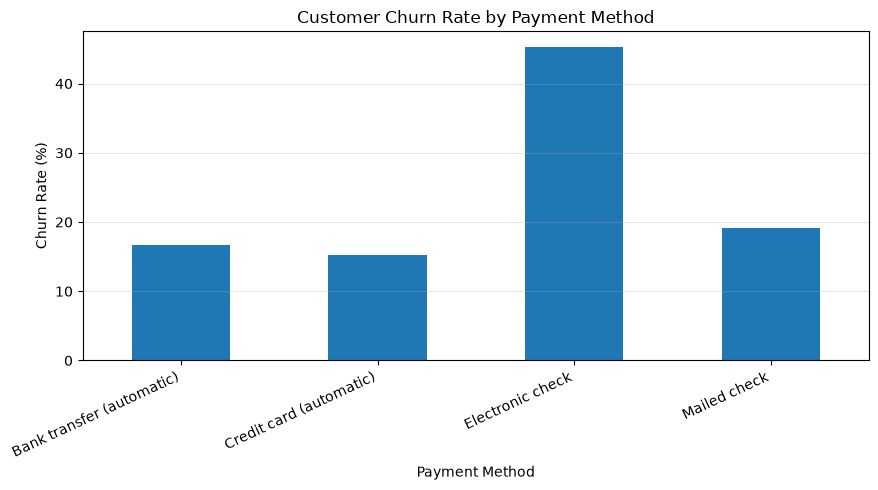

In [18]:
plt.figure(figsize=(9, 5))

payment_churn['Yes'].plot(kind='bar')

plt.title('Customer Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Calculate churn rate by senior citizen status

senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

print("CHURN RATE BY SENIOR CITIZEN STATUS:")
display(senior_churn.round(2))

CHURN RATE BY SENIOR CITIZEN STATUS:


Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


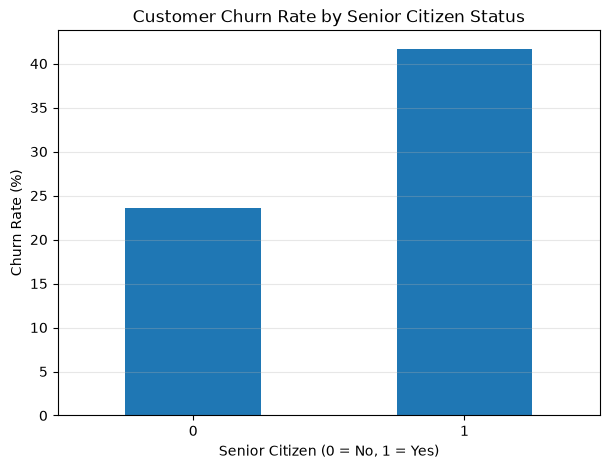

In [20]:
plt.figure(figsize=(7, 5))

senior_churn['Yes'].plot(kind='bar')

plt.title('Customer Churn Rate by Senior Citizen Status')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [21]:
# Calculate churn rate by partner status

partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

print("CHURN RATE BY PARTNER STATUS:")
display(partner_churn.round(2))

CHURN RATE BY PARTNER STATUS:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


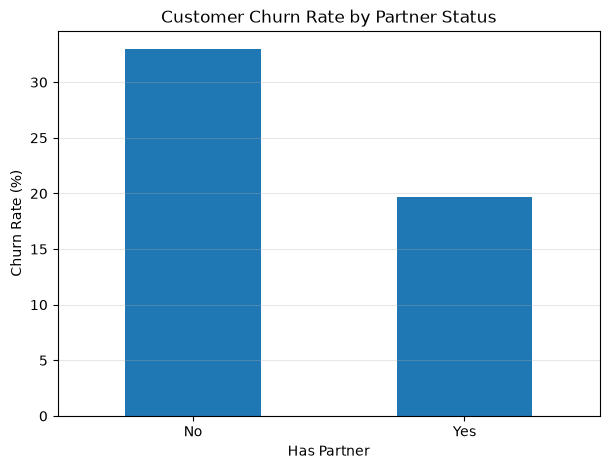

In [22]:
plt.figure(figsize=(7, 5))

partner_churn['Yes'].plot(kind='bar')

plt.title('Customer Churn Rate by Partner Status')
plt.xlabel('Has Partner')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [23]:
dependent_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

print("CHURN RATE BY DEPENDENTS STATUS:")
display(dependent_churn.round(2))

CHURN RATE BY DEPENDENTS STATUS:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


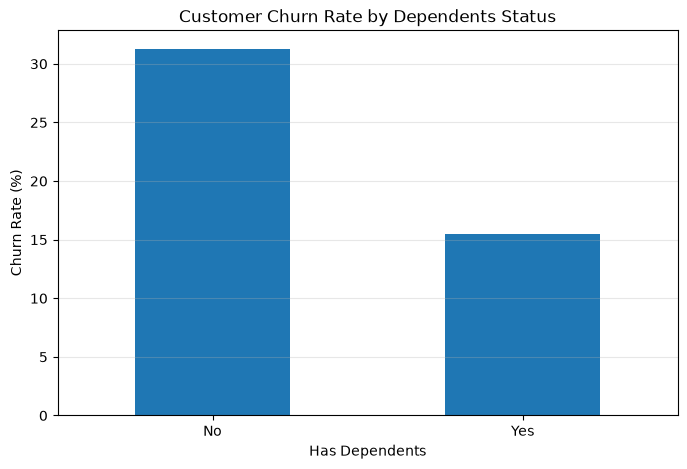

In [24]:
dependent_churn['Yes'].plot(
    kind='bar',
    title='Customer Churn Rate by Dependents Status',
    xlabel='Has Dependents',
    ylabel='Churn Rate (%)',
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

    ## Key Business Findings

1. Overall customer churn rate is 26.54%.
2. Month-to-month contract customers have the highest churn rate (42.71%).
3. Customers with 0–12 months tenure have the highest churn rate (47.44%).
4. Fiber optic customers show a high churn rate (41.89%).
5. Electronic check users have the highest payment-method churn (45.29%).
6. Senior citizens have a higher churn rate (41.68%).
7. Customers without partners have higher churn (32.96%).
8. Customers without dependents have higher churn (31.28%).

### Business Recommendation

Focus retention efforts on new customers, month-to-month subscribers, fiber optic users, and electronic check users through personalised offers, improved support, and long-term contract incentives.

In [25]:
SELECT
    TechSupport,
    Churn,
    COUNT(*) AS customer_count
FROM telecom_customers
GROUP BY TechSupport, Churn
ORDER BY TechSupport, Churn;

IndentationError: unexpected indent (4089939629.py, line 2)

In [26]:
SELECT
    TechSupport,
    Churn,
    COUNT(*) AS customer_count
FROM telecom_customers
GROUP BY TechSupport, Churn
ORDER BY TechSupport, Churn;

IndentationError: unexpected indent (4089939629.py, line 2)